# Módulo 1 — Sumas de Riemann (prototipo en Python)

**Proyecto:** Cálculo Integral Interactivo · Matemáticas II · UTP

En este cuaderno implementamos **desde cero** (solo con NumPy) las sumas de Riemann izquierda, derecha y del punto medio, y comprobamos que dan los mismos resultados que el visualizador web del módulo 1.

**Qué vas a hacer**
1. Escribir la función `riemann` y probarla con los dos ejemplos resueltos del módulo.
2. Comparar con el valor exacto (calculado con SymPy).
3. Ver cómo el error baja al aumentar $n$.

> Si SymPy no estuviera disponible en tu entorno, ejecuta primero `!pip install sympy` en una celda.

## 1. Preparación
Ejecuta la celda para cargar las bibliotecas y una función auxiliar (`preparar`).

In [1]:
# --- Bibliotecas que usaremos ---
import numpy as np                 # cálculo numérico con arreglos
import matplotlib.pyplot as plt    # gráficas
import sympy as sp                 # matemática simbólica: SOLO para el valor exacto y para verificar
                                   # (los algoritmos numéricos los escribimos nosotros desde cero)

x = sp.symbols("x")                # símbolo matemático "x" para SymPy

def preparar(expr, a, b):
    """Convierte una expresión de SymPy en (f_numpy, valor_exacto).
    - f_numpy: función que acepta arreglos de NumPy.
    - valor_exacto: integral definida exacta (Teorema Fundamental del Cálculo), como número decimal."""
    f = sp.lambdify(x, expr, "numpy")
    exacto = float(sp.integrate(expr, (x, a, b)))
    return f, exacto

## 2. La idea

Dividimos $[a,b]$ en $n$ franjas de ancho $\Delta x=\dfrac{b-a}{n}$ y sumamos las áreas de los rectángulos:

$$L_n=\Delta x\sum_{i=0}^{n-1} f(x_i),\qquad R_n=\Delta x\sum_{i=1}^{n} f(x_i),\qquad M_n=\Delta x\sum_{i=1}^{n} f\!\left(\tfrac{x_{i-1}+x_i}{2}\right)$$

La única diferencia es **dónde** medimos la altura de cada rectángulo.

## 3. Implementación desde cero

In [2]:
def riemann(f, a, b, n, tipo="izq"):
    """Suma de Riemann de f en [a, b] con n rectángulos.
    tipo: "izq" (extremo izquierdo), "der" (extremo derecho) o "medio" (punto medio)."""
    dx = (b - a) / n                 # ancho de cada franja
    i = np.arange(n)                 # índices 0, 1, ..., n-1 (uno por franja)
    if tipo == "izq":
        puntos = a + i * dx          # extremo izquierdo de cada franja
    elif tipo == "der":
        puntos = a + (i + 1) * dx    # extremo derecho
    elif tipo == "medio":
        puntos = a + (i + 0.5) * dx  # centro de la franja
    else:
        raise ValueError("tipo debe ser 'izq', 'der' o 'medio'")
    return np.sum(f(puntos)) * dx    # suma de alturas × ancho

## 4. Ejemplo 1 del módulo: $\int_0^2 x^2\,dx$ con $n=4$

In [3]:
f1, exacto1 = preparar(x**2, 0, 2)

L = riemann(f1, 0, 2, 4, "izq")
R = riemann(f1, 0, 2, 4, "der")
M = riemann(f1, 0, 2, 4, "medio")
print(f"Izquierda   L4 = {L:.5f}   (a mano: 1.75)")
print(f"Derecha     R4 = {R:.5f}   (a mano: 3.75)")
print(f"Punto medio M4 = {M:.5f}   (a mano: 2.625)")
print(f"Valor exacto   = {exacto1:.5f}   (8/3)")

# "assert" detiene el programa si la afirmación es falsa: así comprobamos que todo coincide.
assert np.isclose(L, 1.75) and np.isclose(R, 3.75) and np.isclose(M, 2.625)
print("\n✔ Coincide con el cálculo manual del módulo 1")

Izquierda   L4 = 1.75000   (a mano: 1.75)
Derecha     R4 = 3.75000   (a mano: 3.75)
Punto medio M4 = 2.62500   (a mano: 2.625)
Valor exacto   = 2.66667   (8/3)

✔ Coincide con el cálculo manual del módulo 1


## 5. Ejemplo 2 del módulo: $\int_0^\pi \operatorname{sen}(x)\,dx$ con $n=4$

In [4]:
f2, exacto2 = preparar(sp.sin(x), 0, sp.pi)
b2 = float(sp.pi)

L = riemann(f2, 0, b2, 4, "izq")
R = riemann(f2, 0, b2, 4, "der")
M = riemann(f2, 0, b2, 4, "medio")
print(f"L4 = {L:.5f}   R4 = {R:.5f}   M4 = {M:.5f}   exacto = {exacto2:.5f}")

assert np.isclose(L, 1.89612, atol=1e-5) and np.isclose(R, 1.89612, atol=1e-5) and np.isclose(M, 2.05234, atol=1e-5)
print("✔ Coincide con el ejemplo 2 del módulo 1 (L4 = R4 ≈ 1.8961, M4 ≈ 2.0523)")

L4 = 1.89612   R4 = 1.89612   M4 = 2.05234   exacto = 2.00000
✔ Coincide con el ejemplo 2 del módulo 1 (L4 = R4 ≈ 1.8961, M4 ≈ 2.0523)


## 6. Visualización de los rectángulos

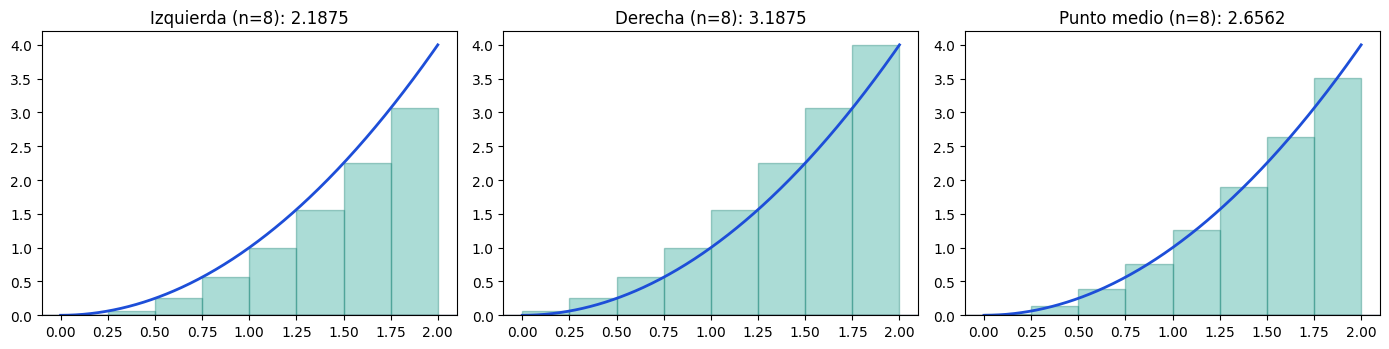

In [5]:
def dibujar_riemann(f, a, b, n, tipo, ax, titulo):
    xs = np.linspace(a, b, 400)
    ax.plot(xs, f(xs), lw=2, color="#1d4ed8")             # la curva
    dx = (b - a) / n
    izq = a + np.arange(n) * dx                           # borde izquierdo de cada barra
    altura_en = {"izq": izq, "der": izq + dx, "medio": izq + dx / 2}[tipo]
    ax.bar(izq, f(altura_en), width=dx, align="edge",     # una barra por franja
           alpha=0.35, color="#0f9d8a", edgecolor="#0b7a6b")
    ax.axhline(0, color="#14213d", lw=1)
    ax.set_title(titulo)

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, tipo, nombre in zip(ejes, ["izq", "der", "medio"], ["Izquierda", "Derecha", "Punto medio"]):
    valor = riemann(f1, 0, 2, 8, tipo)
    dibujar_riemann(f1, 0, 2, 8, tipo, ax, f"{nombre} (n=8): {valor:.4f}")
plt.tight_layout()
plt.show()

## 7. Convergencia: ¿cómo baja el error al aumentar $n$?

     n |      error L |      error R |      error M
----------------------------------------------------
     4 |    9.167e-01 |    1.083e+00 |    4.167e-02
     8 |    4.792e-01 |    5.208e-01 |    1.042e-02
    16 |    2.448e-01 |    2.552e-01 |    2.604e-03
    32 |    1.237e-01 |    1.263e-01 |    6.510e-04
    64 |    6.217e-02 |    6.283e-02 |    1.628e-04
   128 |    3.117e-02 |    3.133e-02 |    4.069e-05
   256 |    1.560e-02 |    1.565e-02 |    1.017e-05
   512 |    7.807e-03 |    7.818e-03 |    2.543e-06
  1024 |    3.905e-03 |    3.908e-03 |    6.358e-07


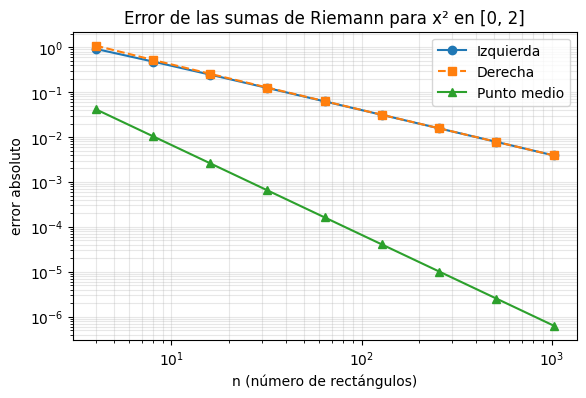

In [6]:
ns = [4, 8, 16, 32, 64, 128, 256, 512, 1024]
print(f"{'n':>6} | {'error L':>12} | {'error R':>12} | {'error M':>12}")
print("-" * 52)
err_L, err_R, err_M = [], [], []
for n in ns:
    eL = abs(riemann(f1, 0, 2, n, "izq") - exacto1)
    eR = abs(riemann(f1, 0, 2, n, "der") - exacto1)
    eM = abs(riemann(f1, 0, 2, n, "medio") - exacto1)
    err_L.append(eL); err_R.append(eR); err_M.append(eM)
    print(f"{n:>6} | {eL:>12.3e} | {eR:>12.3e} | {eM:>12.3e}")

plt.figure(figsize=(6.5, 4))
plt.loglog(ns, err_L, "o-", label="Izquierda")
plt.loglog(ns, err_R, "s--", label="Derecha")
plt.loglog(ns, err_M, "^-", label="Punto medio")
plt.xlabel("n (número de rectángulos)")
plt.ylabel("error absoluto")
plt.title("Error de las sumas de Riemann para x² en [0, 2]")
plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.show()

## Preguntas para pensar

1. Cuando duplicas $n$, ¿por cuánto se divide aproximadamente el error de la suma izquierda? ¿Y el del punto medio? (Mira la tabla.)
2. ¿Por qué la izquierda **subestima** y la derecha **sobreestima** para $x^2$ en $[0,2]$? ¿Qué pasaría con $f(x)=e^{-x}$?
3. **Ejercicio:** cambia `x**2` por otra expresión de SymPy (por ejemplo `sp.exp(x)`) y otro intervalo, y comprueba que el error sigue disminuyendo.